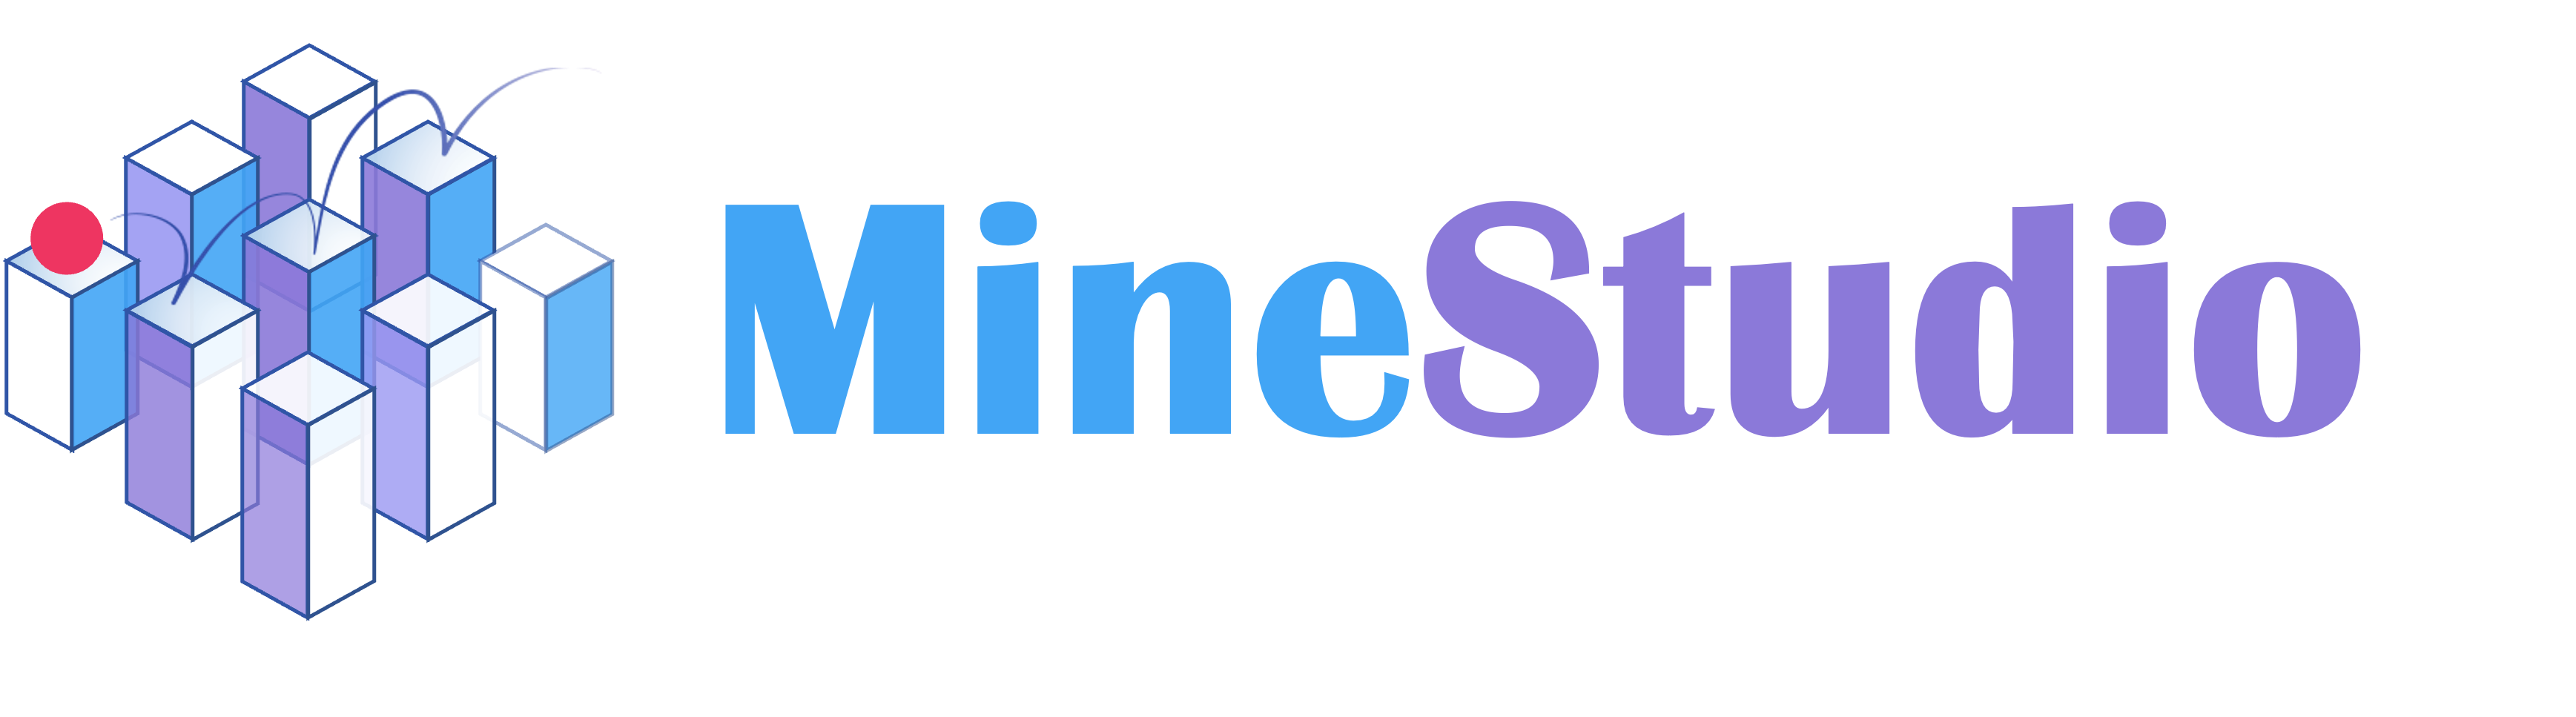

https://craftjarvis.github.io/MineStudio/overview/getting-started.html

Another promising dataset: **MineRL BASALT 2022 Dataset**

In [1]:
from dotenv import load_dotenv

load_dotenv()  # Reads the .env file and sets HF_TOKEN in os.environ

True

In [2]:
import minestudio

In [ ]:
from minestudio.data import RawDataset
from minestudio.data.minecraft.callbacks import ImageKernelCallback, ActionKernelCallback

dataset = RawDataset(
    dataset_dirs=[
        '6xx', 
        '7xx', 
        '8xx', 
        '9xx', 
        '10xx', 
    ],
    modal_kernel_callbacks=[
        ImageKernelCallback(frame_width=224, frame_height=224, enable_video_aug=False), 
        ActionKernelCallback(enable_prev_action=True, win_bias=1, read_bias=-1),
    ],
    win_len=128, 
    split_ratio=0.9,
    shuffle_episodes=True,
)
item = dataset[0]
print(item.keys())

Download Dataset
        Dataset: 6xx
        Base Dir: /tmp/MineStudio
        Total Size: 219.28 GB
        Free Space: 912.29 GB

Fetching 76 files:  62%|██████▏   | 47/76 [00:40<00:08,  3.29it/s]

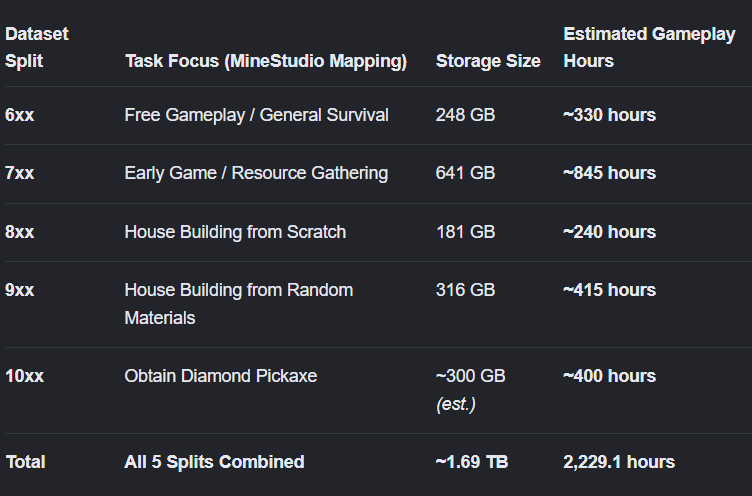

This is a lot. Let's download like 5% of 6xx (=12.4GB) to test out the architecture. Then donwload 10% of all (=179GB) to create the first mid scale version. Then train on the full data using a cloud prov.

6xx: https://huggingface.co/datasets/CraftJarvis/minestudio-data-6xx-v110

In [ ]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="CraftJarvis/minestudio-data-6xx-v110",
    repo_type="dataset",
    allow_patterns=["*1900*", "*.json", "*.yaml"],
    local_dir="../data/minestudio_6xx_1900"
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
import sys
print(sys.executable)

/workspace/.venv/bin/python
